# Introduction 

Breast cancer can be classified into 4 subtypes: Luminal A, Luminal B, HER2-positive, and Basal-like. While these subtypes are often classified based on estrogen receptors (ER), progesterone receptors (PR), and HER2 expression for determining treatment plans, the PAM50 assay measures the expression levels of 50 genes and is useful in determining a patient's prognosis and can more accurately classify subtypes compared to more basic IHC methods. However, measuring the expression levels for 50 genes can be costly. The aim of this analysis is to use principal component analysis (PCA) to identify which genes in the PAM50 assay are most important in classification, with the hope of being able to propose a list of fewer genes that could still accurately classify breast cancer subtype, thereby reducing costs.

# Libraries to be Used

In [1]:
# Import relevant libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

In [2]:
# Load in data
pam50_df = pd.read_csv("pam50_df.csv")
pam50_df.head(5)

,Complete TCGA ID,PAM50 mRNA,CENPF,MKI67,KRT5,KRT14,ERBB2,EGFR,MAPT,MAPT.1,...,CXXC5,UBE2T,CDC20,MELK,SLC39A6,BCL2,EXO1,BIRC5,CCNE1,MYC
0,TCGA-A2-A0CM,Basal-like,2.160157,2.623021,4.768355,4.933663,-4.419112,-0.271711,-6.013418,-6.318320,...,-1.292949,3.541400,3.177722,0.025707,-1.792547,-0.545317,-0.525428,2.516489,2.556897,-2.574896
1,TCGA-BH-A18Q,Basal-like,-0.179342,-1.463969,2.182497,2.399947,-5.187379,-1.922286,-8.218295,-8.188186,...,-2.624816,-0.717949,0.539915,0.001309,-0.641005,-0.627623,-0.525428,-0.888563,-3.581595,-2.574896
2,TCGA-A7-A0CE,Basal-like,1.761673,-0.583448,5.542903,2.080457,-3.099008,-1.009547,-3.556670,-3.556670,...,-3.329417,1.922643,2.935811,0.025707,-2.253124,-3.430418,-0.525428,0.997851,1.209322,-2.574896
3,TCGA-D8-A142,Basal-like,-0.415696,-1.232627,-2.823113,0.668726,-3.130366,-0.462687,-6.195666,-6.427009,...,-2.320664,-1.232627,-1.438667,0.025707,-0.269519,-0.910915,-0.525428,-0.075910,-0.101213,-7.659635
4,TCGA-AO-A0J6,Basal-like,-0.075090,-1.159168,0.650452,0.661745,-2.062567,-0.394103,-0.893795,-0.913557,...,-0.577605,-2.003281,-4.278717,-0.125906,-3.451542,-0.176722,1.567966,-0.859917,0.666715,-2.574896


In [4]:
# Split data into features and target
pam50_features = pam50_df.iloc[:, 2:]
pam50_target = pam50_df["PAM50 mRNA"]

One way to determine which features can be removed is by determining which genes are correlated with each other. We can visualize this with a heatmap.

<Axes: >

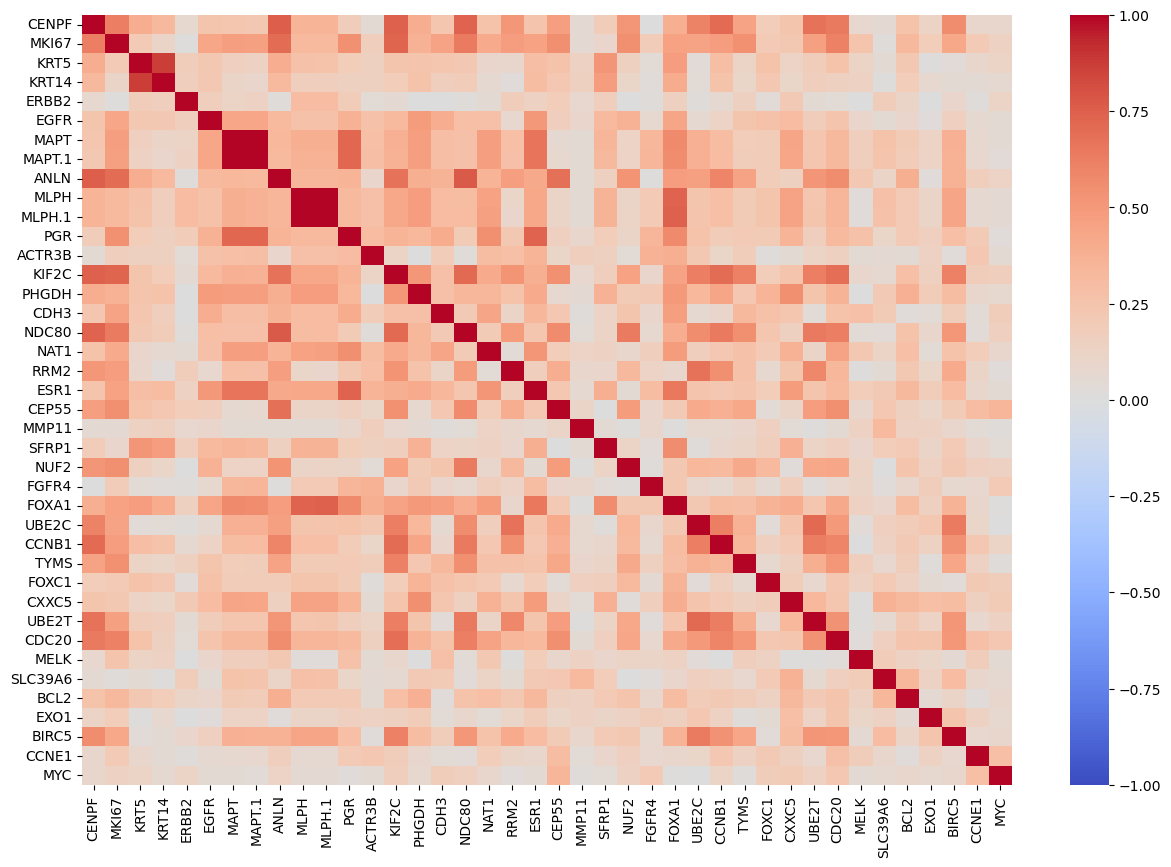

In [19]:
# PLot correlation heatmap of genes
plt.figure(figsize=(15, 10))
sns.heatmap(abs(pam50_features.corr()), annot=False, cmap="coolwarm", vmin=-1, vmax=1)

Blue indicates that two genes have a negative correlation while red indicates a positive correlation. More importantly, the darker the color (whether red or blue), the stronger the correlation. There appear to be no negative correlations between genes. As for positive correlations, there are a few strong ones, such as between FOXA1 and MLPH. However, these observations are not enough to dismiss a gene as redundant since there are no genes that are highly correlated with a lot of genes.

Let's apply PCA to our data and see how many principal components (PCs) account for 95% of the variance.

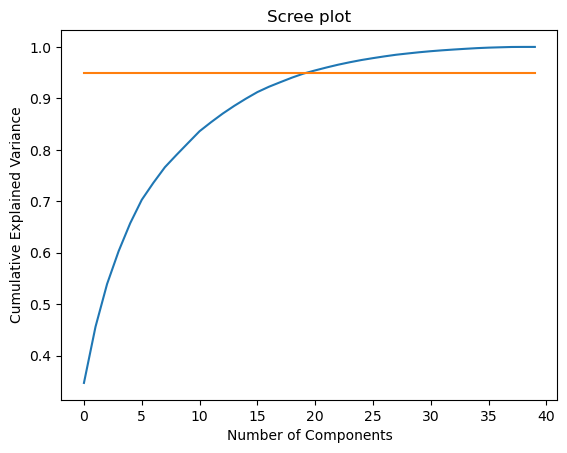

In [12]:
# Apply PCA to features
pca = PCA()
pam50_transformed = pca.fit_transform(pam50_features)

# Display Scree plot of principal components
plt.figure()
plt.plot(np.cumsum(pca.explained_variance_ratio_))
# Plot a straight line at cumulative explained variance = 0.95
plt.plot([0.95] * len(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title("Scree plot")
plt.show()

Based on the plot, it seems that 95% of the variance is explained by just 20 PCs. To understand which genes were most important for describing the variability in the data, we would look at the loading scores for each gene in each PC. Let's start by looking at PC1.

In [13]:
# Loading scores for each gene in PC1
loading_scores = pd.Series(pca.components_[0], index=pam50_features.columns)
pc1_loading_scores = loading_scores.abs().sort_values(ascending=False)
pc1_loading_scores

MAPT.1     0.401188
MAPT       0.392312
PGR        0.351419
NAT1       0.318670
ESR1       0.277248
FOXA1      0.206313
SFRP1      0.179137
PHGDH      0.175052
MLPH.1     0.160494
MLPH       0.159717
MKI67      0.143196
ANLN       0.142159
EGFR       0.140704
KRT5       0.134755
CDC20      0.132344
CXXC5      0.123789
UBE2C      0.101977
CDH3       0.101891
KIF2C      0.096180
CCNB1      0.094781
FGFR4      0.092609
KRT14      0.092257
NDC80      0.089919
BIRC5      0.086594
TYMS       0.083180
UBE2T      0.077321
CENPF      0.072515
BCL2       0.068674
FOXC1      0.062677
CEP55      0.057929
SLC39A6    0.056729
RRM2       0.054860
NUF2       0.054318
ACTR3B     0.037700
MELK       0.030019
CCNE1      0.028773
ERBB2      0.022994
EXO1       0.019211
MMP11      0.008496
MYC        0.002968
dtype: float64

The loading scores indicate the importance of each gene in describing the principal component. The higher the loading score, the more important the gene is for that principal component. In PC1, for instance, the most important genes are MAPT.1, MAPT, PGR, and so on.